# Model notebook template (CSCI167 Rotten Tomatoes project)

Make **your own copy** of this notebook for your architecture (File > Save a copy in Drive, or copy the file
in the repo, e.g. `notebooks/<yourname>_<model>.ipynb`).

Everything in here is **shared code that all of us use**: setup, data and splits, the common training settings,
the run function, the results table, learning curves and error analysis. Do not edit `common.py` or the shared
settings, so that all models are trained and evaluated the same way and the results are comparable.
The only part you write is the architecture, in the cell(s) under **YOUR ARCHITECTURE**.

Colab: Runtime > Change runtime type > GPU (T4), then run cells top to bottom.

In [22]:
%pip install -q datasets transformers
import os
if not os.path.exists("common.py"):
    REPO_URL = "https://github.com/ZhongVang/csci167-rotten-tomatoes.git"   # group repo (private until submission)
    !git clone $REPO_URL project
    %cd project

In [23]:
# Optional (Colab): keep results on Drive so they survive session timeouts.
# Must run BEFORE `import common`.
try:
    from google.colab import drive
    drive.mount('/content/drive')
    os.environ["RESULTS_DIR"] = "/content/drive/MyDrive/CSCI167_results"
except Exception:
    pass  # running locally: results go to ./results

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [24]:
OWNER = "Zhong"                   # TODO: your name; results go to results_<OWNER>.csv
RESULTS_FILE = f"results_{OWNER}.csv"
SEEDS = [0, 1, 2]                    # shared: do not change

import numpy as np, torch, torch.nn as nn, torch.nn.functional as F
from common import *

print(save_env_info(OWNER))          # package versions + hardware, for the report
data = load_data()
print({k: len(v[0]) for k, v in data.items()}, "-> train/val/test sizes")
print("label counts (train):", np.bincount(data["train"][1]))
print("example:", data["train"][0][0], "->", data["train"][1][0])

{'python': '3.13.16', 'torch': '2.14.1+cu130', 'numpy': '2.4.6', 'cuda': '13.0', 'gpu': 'Tesla T4', 'common_version': '65ca4193', 'datasets': '4.8.5', 'transformers': '5.22.1', 'pandas': '2.2.3', 'scikit-learn': '1.6.1', 'dataset_revision': 'aa13bc287fa6fcab6daf52f0dfb9994269ffea28', 'dataset_id': 'cornell-movie-review-data/rotten_tomatoes'}
{'train': 8530, 'validation': 1066, 'test': 1066} -> train/val/test sizes
label counts (train): [4265 4265]
example: the rock is destined to be the 21st century's new " conan " and that he's going to make a splash even greater than arnold schwarzenegger , jean-claud van damme or steven segal . -> 1


## Shared training settings (do not change for the main runs)

Every model in the group is trained with the same budget so the comparison is fair: Adam, lr 1e-3, batch 64,
at most 20 epochs, early stopping (patience 5) on **validation** accuracy; the best-validation weights are
restored and the test set is evaluated once at the end. The same 3 seeds are used for 100%, 25% and 10% of the
training data. Data: official splits of `cornell-movie-review-data/rotten_tomatoes`
(train 8,530 / validation 1,066 / test 1,066).

In [25]:
TAG = "tfm"               # TODO: short unique name used in run names / files (e.g. "cnn")
MODEL_NAME = "Transformer (scratch)"       # TODO: descriptive name shown in the results table

PROTOCOL = dict(optimizer="adam", lr=1e-3, batch_size=64, epochs=20, patience=5)
FRACS = [1.0, 0.25, 0.1]

def run(seed, frac, tag=None, **overrides):
    """Train + evaluate one run and log it to results/<RESULTS_FILE>.
    overrides: training settings (optimizer, lr, weight_decay, schedule, momentum) go to the trainer;
    anything else is passed to MyModel(...) as a model hyperparameter (e.g. dropout=0.0)."""
    train_keys = {"optimizer", "lr", "weight_decay", "schedule", "momentum"}
    tcfg = {**PROTOCOL, **{k: v for k, v in overrides.items() if k in train_keys}}
    mcfg = {k: v for k, v in overrides.items() if k not in train_keys}
    set_seed(seed)                                    # BEFORE building the model
    train_dl, val_dl, test_dl, vocab = make_vocab_loaders(data, tcfg["batch_size"], seed, train_frac=frac)
    model = MyModel(len(vocab), **mcfg)
    return train_and_eval(model, (train_dl, val_dl, test_dl), run_name=f"{tag or TAG}_f{frac}_s{seed}",
                          model_name=MODEL_NAME, seed=seed, train_frac=frac, extra=mcfg,
                          results_file=RESULTS_FILE, **tcfg)

## YOUR ARCHITECTURE

The architectures have not been chosen yet. Add your own code cell(s) below this one and define your model there.
You can build any deep learning architecture suited to text classification, as long as it is different from the
other group members' models. Some starting points (not a requirement): a fully connected network on pooled word
embeddings, a 1D CNN, an RNN/LSTM, a transformer, or a pretrained model (`HFClassifier` in `common.py` wraps a
Hugging Face model, fine-tuned or with a frozen encoder). The course textbook (Understanding Deep Learning)
covers fully connected networks (Ch 3-4), convolutional networks (Ch 10), residual networks (Ch 11) and
transformers (Ch 12).

**What the shared code expects:** a class named `MyModel(nn.Module)` with

- `__init__(self, vocab_size, **your_hyperparameters)`: every extra argument needs a default value, so
  `MyModel(vocab_size)` works. Index 0 is the padding token.
- `forward(self, ids, mask)`: `ids` is a LongTensor `[batch, length]` of token indices, `mask` is a BoolTensor
  `[batch, length]` that is True for real tokens and False for padding. It must return logits of shape
  `[batch, 2]` (class 0 = negative, 1 = positive).

(Pretrained Hugging Face models use their own tokenizer, so they need `make_hf_loaders` and a separate run
function. Ask the group before choosing one, so the comparison stays consistent.)

**Write down for the report:** why you chose this architecture, its structure and trainable parameter count
(printed below), how its depth and layer choices might affect learning, and what is trained or frozen if you
use a pretrained model or library code (cite the source).

**Hyperparameter study (the rubric requires one; the group decides who runs it):** investigate at least two
training factors with at least two settings each, changing one factor at a time versus a reference config, and
choose settings using validation accuracy only. Possible factors: optimizer, learning rate, batch size,
lr schedule, regularization (dropout, weight decay), augmentation. You can run each setting with the shared
function, for example `run(seed, 1.0, tag=TAG + "_sgd", optimizer="sgd", lr=0.05)` for each seed in `SEEDS`,
and compare them in the summary table below (convergence speed, validation accuracy, stability, training time).

In [26]:
class MyModel(nn.Module):
    def __init__(self, vocab_size, d_model=128, n_heads=4, n_layers=2, ff=256, dropout=0.1):
        super().__init__()
        self.emb = nn.Embedding(vocab_size, d_model, padding_idx=PAD)
        self.pos = nn.Embedding(MAX_LEN, d_model)          # learned position embeddings
        layer = nn.TransformerEncoderLayer(d_model, n_heads, ff, dropout, batch_first=True)
        self.enc = nn.TransformerEncoder(layer, n_layers, enable_nested_tensor=False)
        self.head = nn.Linear(d_model, 2)

    def forward(self, ids, mask):
        pos = torch.arange(ids.size(1), device=ids.device)
        x = self.emb(ids) + self.pos(pos)                  # words + positions
        x = self.enc(x, src_key_padding_mask=~mask)        # attention ignores padding
        m = mask.unsqueeze(-1).float()
        pooled = (x * m).sum(1) / m.sum(1).clamp(min=1)    # average over real words
        return self.head(pooled)                           # logits [batch, 2]

## Sanity check (run once your model is defined)

Builds your model, prints its structure and trainable parameter count (needed for the report), and checks
the output shape on a real batch. Then run one short test (10% of the data) before the full runs.

In [27]:
set_seed(0)
train_dl, val_dl, test_dl, vocab = make_vocab_loaders(data, 64, 0)
model = MyModel(len(vocab))
print(model)
print("trainable / total params:", count_params(model))
inputs, y = next(iter(train_dl))
out = model(**inputs)
assert out.shape == (len(y), 2), f"forward() must return logits of shape [batch, 2], got {tuple(out.shape)}"
print("OK: logits", tuple(out.shape), "| ids", tuple(inputs['ids'].shape))

MyModel(
  (emb): Embedding(8981, 128, padding_idx=0)
  (pos): Embedding(64, 128)
  (enc): TransformerEncoder(
    (layers): ModuleList(
      (0-1): 2 x TransformerEncoderLayer(
        (self_attn): MultiheadAttention(
          (out_proj): NonDynamicallyQuantizableLinear(in_features=128, out_features=128, bias=True)
        )
        (linear1): Linear(in_features=128, out_features=256, bias=True)
        (dropout): Dropout(p=0.1, inplace=False)
        (linear2): Linear(in_features=256, out_features=128, bias=True)
        (norm1): LayerNorm((128,), eps=1e-05, elementwise_affine=True, bias=True)
        (norm2): LayerNorm((128,), eps=1e-05, elementwise_affine=True, bias=True)
        (dropout1): Dropout(p=0.1, inplace=False)
        (dropout2): Dropout(p=0.1, inplace=False)
      )
    )
  )
  (head): Linear(in_features=128, out_features=2, bias=True)
)
trainable / total params: (1422978, 1422978)
OK: logits (64, 2) | ids (64, 46)


In [28]:
run(0, 0.1, tag=TAG + '_test')   # quick test: if validation accuracy is above 50%, launch the full runs

[tfm_test_f0.1_s0] ep 01 train_loss 0.7694 train_acc 0.4812 val_loss 0.6885 val_acc 0.5469
[tfm_test_f0.1_s0] ep 02 train_loss 0.6935 train_acc 0.5176 val_loss 0.7003 val_acc 0.5075
[tfm_test_f0.1_s0] ep 03 train_loss 0.6538 train_acc 0.6408 val_loss 0.6971 val_acc 0.5563
[tfm_test_f0.1_s0] ep 04 train_loss 0.5856 train_acc 0.6890 val_loss 0.7868 val_acc 0.5525
[tfm_test_f0.1_s0] ep 05 train_loss 0.4693 train_acc 0.7840 val_loss 0.9776 val_acc 0.5544
[tfm_test_f0.1_s0] ep 06 train_loss 0.3594 train_acc 0.8427 val_loss 1.0890 val_acc 0.5441
[tfm_test_f0.1_s0] ep 07 train_loss 0.1965 train_acc 0.9237 val_loss 2.0161 val_acc 0.5338
[tfm_test_f0.1_s0] ep 08 train_loss 0.1883 train_acc 0.9261 val_loss 1.4653 val_acc 0.5732
[tfm_test_f0.1_s0] ep 09 train_loss 0.0426 train_acc 0.9906 val_loss 1.7601 val_acc 0.5600
[tfm_test_f0.1_s0] ep 10 train_loss 0.0113 train_acc 0.9988 val_loss 2.0996 val_acc 0.5779
[tfm_test_f0.1_s0] ep 11 train_loss 0.0034 train_acc 1.0000 val_loss 2.3847 val_acc 0.5760

{'timestamp': '2026-11-20T03:51:03',
 'run_name': 'tfm_test_f0.1_s0',
 'model': 'Transformer (scratch)',
 'seed': 0,
 'train_frac': 0.1,
 'n_train': 852,
 'n_val': 1066,
 'n_test': 1066,
 'optimizer': 'adam',
 'lr': 0.001,
 'weight_decay': 0.0,
 'schedule': 'constant',
 'batch_size': 64,
 'epochs_max': 20,
 'patience': 5,
 'epochs_run': 15,
 'best_epoch': 10,
 'best_val_acc': 0.5779,
 'test_acc': 0.5863,
 'test_f1': 0.5863,
 'trainable_params': 465282,
 'total_params': 465282,
 'train_seconds': 3.1,
 'device': 'cuda',
 'common_version': '65ca4193',
 'extra': '{}'}

In [29]:
os.remove(f"{RESULTS_DIR}/{RESULTS_FILE}")

## Main runs: 3 seeds x 100% / 25% / 10% of the training data

In [30]:
for frac in FRACS:
    for seed in SEEDS:
        run(seed, frac)

[tfm_f1.0_s0] ep 01 train_loss 0.6737 train_acc 0.5743 val_loss 0.6591 val_acc 0.6173
[tfm_f1.0_s0] ep 02 train_loss 0.5820 train_acc 0.6917 val_loss 0.6705 val_acc 0.6492
[tfm_f1.0_s0] ep 03 train_loss 0.4682 train_acc 0.7777 val_loss 0.6760 val_acc 0.6604
[tfm_f1.0_s0] ep 04 train_loss 0.3331 train_acc 0.8566 val_loss 0.7261 val_acc 0.6886
[tfm_f1.0_s0] ep 05 train_loss 0.1991 train_acc 0.9257 val_loss 0.8645 val_acc 0.6623
[tfm_f1.0_s0] ep 06 train_loss 0.1215 train_acc 0.9538 val_loss 1.1147 val_acc 0.6801
[tfm_f1.0_s0] ep 07 train_loss 0.0812 train_acc 0.9712 val_loss 1.3615 val_acc 0.6961
[tfm_f1.0_s0] ep 08 train_loss 0.0458 train_acc 0.9848 val_loss 1.6704 val_acc 0.6867
[tfm_f1.0_s0] ep 09 train_loss 0.0307 train_acc 0.9896 val_loss 1.6943 val_acc 0.7008
[tfm_f1.0_s0] ep 10 train_loss 0.0436 train_acc 0.9836 val_loss 1.6217 val_acc 0.6942
[tfm_f1.0_s0] ep 11 train_loss 0.0278 train_acc 0.9909 val_loss 1.8523 val_acc 0.6867
[tfm_f1.0_s0] ep 12 train_loss 0.0275 train_acc 0.9893

## Results: summary table, learning curves, error analysis

In [31]:
summarize(f'results_{OWNER}.csv')   # mean +/- std over seeds, per configuration

,model,train_frac,optimizer,lr,weight_decay,schedule,batch_size,extra,n_seeds,val_acc,val_std,test_acc,test_std,test_f1,params,seconds
0,Transformer (scratch),0.10,adam,0.001,0.0,constant,64,{},3,0.5751,0.0075,0.5788,0.0107,0.5750,465282,2.4667
1,Transformer (scratch),0.25,adam,0.001,0.0,constant,64,{},3,0.6335,0.0061,0.6251,0.0039,0.6239,701698,7.2667
2,Transformer (scratch),1.00,adam,0.001,0.0,constant,64,{},3,0.7111,0.0103,0.7111,0.0188,0.7110,1422978,20.8333


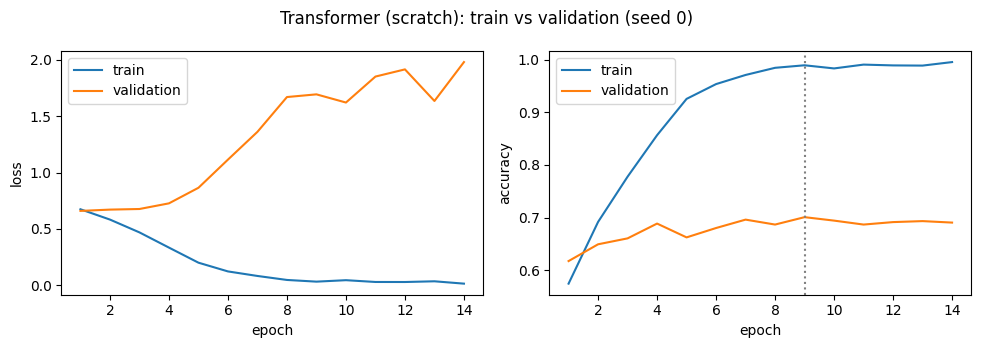

In [32]:
plot_history(f"{TAG}_f1.0_s0", f"{MODEL_NAME}: train vs validation (seed 0)");

In [33]:
import json
h = json.load(open(f"{RESULTS_DIR}/history/{TAG}_f1.0_s0.json"))
preds, labels = np.array(h["test_preds"]), np.array(data["test"][1])
texts = data["test"][0]
cm = np.zeros((2, 2), int)
for y, p in zip(labels, preds): cm[y, p] += 1
print("confusion matrix (rows=true neg/pos, cols=pred neg/pos):\n", cm)
wrong = np.where(preds != labels)[0]
print(len(wrong), "errors. Examples (true, pred, text):")
rng = np.random.default_rng(0)
for i in rng.choice(wrong, 20, replace=False): print(labels[i], preds[i], "|", texts[i])

confusion matrix (rows=true neg/pos, cols=pred neg/pos):
 [[372 161]
 [128 405]]
289 errors. Examples (true, pred, text):
0 1 | [hell is] looking down at your watch and realizing serving sara isn't even halfway through .
1 0 | a solidly entertaining little film .
1 0 | as action-adventure , this space-based homage to robert louis stevenson's treasure island fires on all plasma conduits .
0 1 | the uneven movie does have its charms and its funny moments but not quite enough of them .
0 1 | the dramatic scenes are frequently unintentionally funny , and the action sequences -- clearly the main event -- are surprisingly uninvolving .
0 1 | certainly beautiful to look at , but its not very informative about its titular character and no more challenging than your average television biopic .
0 1 | none of this has the suavity or classical familiarity of bond , but much of it is good for a laugh . the problem with " xxx " is that its own action isn't very effective .
0 1 | any film that doesn'

In [34]:
vocab = make_vocab_loaders(data, 64, 0)[3]
unk = lambda t: np.mean([w not in vocab for w in t.split()])
right = np.where(preds == labels)[0]
print("unknown-word rate in errors :", np.mean([unk(texts[i]) for i in wrong]))
print("unknown-word rate in correct:", np.mean([unk(texts[i]) for i in right]))

unknown-word rate in errors : 0.08923093375782633
unknown-word rate in correct: 0.0850510365944787


## Notes for the report

- **Design choices:** I used a small encoder-only transformer trained from scratch (Ch 12): a 128-dimensional word embedding plus learned position embeddings, 2 transformer encoder layers with 4 attention heads and a 256-unit feed-forward layer, dropout 0.1, mean pooling over the non-padding words, and a linear layer for the two classes. It has 1,422,978 trainable parameters at 100% of the training data (about 1.15M are the embedding table). The vocabulary is built from training text only, so the parameter count is smaller at 25% (about 700k) and 10% (about 465k) of the data. I kept the model small because there are only 8,530 training sentences, and I expected a from-scratch transformer to overfit, since it has no pretrained knowledge of language.
- **Learning curves:** The model overfits strongly. Training accuracy reaches about 99% while validation accuracy stays near 70%, and validation loss rises from about 0.65 to about 2.0 after epoch 3 while training loss falls to near 0. Early stopping on validation accuracy selected epochs 8-11 at 100% of the data.
- **Errors:** On seed 0 the model makes 289 errors out of 1,066 test sentences (161 positive predicted as negative, 128 negative predicted as positive). From a random sample of 20 errors, most are sentences whose sentiment depends on structure and not on single words: concessions ("certainly beautiful to look at, but its not very informative"), negation ("a thriller without a lot of thrills"), and sarcasm. Unknown words do not explain the errors: 8.9% of tokens in misclassified sentences are out-of-vocabulary versus 8.5% in correctly classified ones.
- **Less data:** Test accuracy (mean over 3 seeds) falls from 71.1% (std 1.9) at 100% of the training data, to 62.5% (std 0.4) at 25%, to 57.9% (std 1.1) at 10%. At 10% the model is only about 8 points above chance.
- **Limitations:** Only 3 seeds, and the standard deviation across seeds at 100% (1.9 points) is large relative to differences we might see between models. The test set has 1,066 sentences, so a single accuracy estimate has roughly a 1.4-point standard error. I used one training configuration (Adam, lr 1e-3, no regularization beyond dropout 0.1) and did not tune it. The error analysis is based on a random sample of 20 errors from one seed, so it is qualitative. The dataset's license is listed as unknown.

In [35]:
# Hyperparameter study: one factor at a time vs the reference (dropout 0.1, weight_decay 0, Adam lr 1e-3).
# The reference runs are the main runs above (tag "tfm"). Full training set, 3 seeds each.
study = [
    dict(tag=TAG + "_do0.3", dropout=0.3),
    dict(tag=TAG + "_do0.5", dropout=0.5),
    dict(tag=TAG + "_wd1e-4", weight_decay=1e-4),
    dict(tag=TAG + "_wd1e-2", weight_decay=1e-2),
]
for cfg in study:
    for seed in SEEDS:
        run(seed, 1.0, **cfg)

[tfm_do0.3_f1.0_s0] ep 01 train_loss 0.6755 train_acc 0.5728 val_loss 0.6615 val_acc 0.6191
[tfm_do0.3_f1.0_s0] ep 02 train_loss 0.5953 train_acc 0.6801 val_loss 0.6900 val_acc 0.6398
[tfm_do0.3_f1.0_s0] ep 03 train_loss 0.4969 train_acc 0.7567 val_loss 0.7095 val_acc 0.6501
[tfm_do0.3_f1.0_s0] ep 04 train_loss 0.3839 train_acc 0.8292 val_loss 0.7084 val_acc 0.6867
[tfm_do0.3_f1.0_s0] ep 05 train_loss 0.2751 train_acc 0.8875 val_loss 0.7963 val_acc 0.6764
[tfm_do0.3_f1.0_s0] ep 06 train_loss 0.1974 train_acc 0.9240 val_loss 0.9161 val_acc 0.6951
[tfm_do0.3_f1.0_s0] ep 07 train_loss 0.1411 train_acc 0.9462 val_loss 1.1110 val_acc 0.6942
[tfm_do0.3_f1.0_s0] ep 08 train_loss 0.1098 train_acc 0.9611 val_loss 1.2794 val_acc 0.7026
[tfm_do0.3_f1.0_s0] ep 09 train_loss 0.0814 train_acc 0.9719 val_loss 1.4500 val_acc 0.6998
[tfm_do0.3_f1.0_s0] ep 10 train_loss 0.0650 train_acc 0.9762 val_loss 1.5539 val_acc 0.6904
[tfm_do0.3_f1.0_s0] ep 11 train_loss 0.0504 train_acc 0.9831 val_loss 1.7880 val

In [36]:
import json, pandas as pd
df = pd.read_csv(f"{RESULTS_DIR}/{RESULTS_FILE}")
df = df[df.train_frac == 1.0].copy()
df["dropout"] = df["extra"].apply(lambda s: json.loads(s).get("dropout", 0.1))
tbl = df.groupby(["dropout", "weight_decay"]).agg(
    n_seeds=("seed", "nunique"),
    val_acc=("best_val_acc", "mean"), val_std=("best_val_acc", "std"),
    test_acc=("test_acc", "mean"), test_std=("test_acc", "std"),
    best_epoch=("best_epoch", "mean"), epochs_run=("epochs_run", "mean"),
    seconds=("train_seconds", "mean")).round(4)
print(tbl)
print("Best setting by VALIDATION accuracy:", tbl["val_acc"].idxmax())

                      n_seeds  val_acc  val_std  test_acc  test_std  \
dropout weight_decay                                                  
0.1     0.0000              3   0.7111   0.0103    0.7111    0.0188   
        0.0001              3   0.7039   0.0078    0.6998    0.0119   
        0.0100              3   0.6810   0.0091    0.6936    0.0147   
0.3     0.0000              3   0.7157   0.0136    0.7145    0.0085   
0.5     0.0000              3   0.7208   0.0101    0.7330    0.0094   

                      best_epoch  epochs_run  seconds  
dropout weight_decay                                   
0.1     0.0000            9.3333     14.3333  20.8333  
        0.0001           12.6667     16.3333  21.5333  
        0.0100           19.6667     20.0000  26.7000  
0.3     0.0000            8.6667     13.6667  18.0333  
0.5     0.0000            9.6667     14.6667  19.6667  
Best setting by VALIDATION accuracy: (np.float64(0.5), np.float64(0.0))


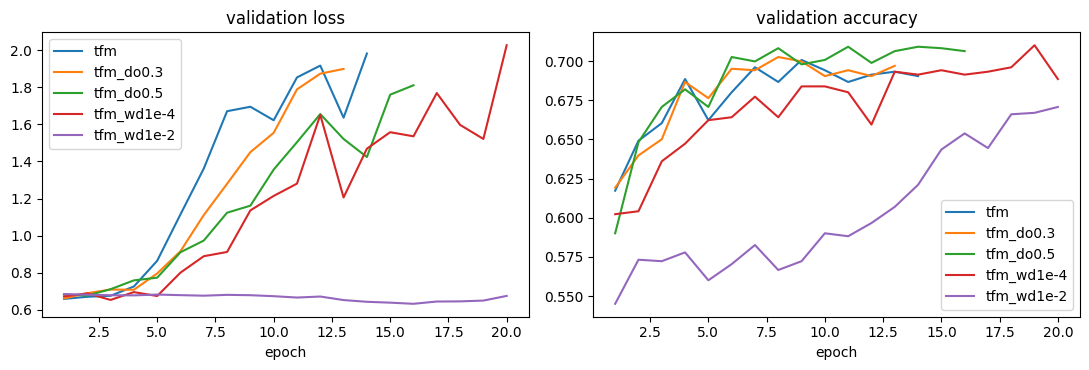

In [37]:
import matplotlib.pyplot as plt
tags = [TAG, TAG + "_do0.3", TAG + "_do0.5", TAG + "_wd1e-4", TAG + "_wd1e-2"]
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
for t in tags:
    h = json.load(open(f"{RESULTS_DIR}/history/{t}_f1.0_s0.json"))
    ax[0].plot(range(1, len(h["val_loss"]) + 1), h["val_loss"], label=t)
    ax[1].plot(range(1, len(h["val_acc"]) + 1), h["val_acc"], label=t)
ax[0].set_title("validation loss"); ax[1].set_title("validation accuracy")
for a in ax: a.set_xlabel("epoch"); a.legend()
fig.tight_layout();

## Hyperparameter study (transformer, full training set, 3 seeds)

**Search strategy:** one factor at a time against a reference (Adam, lr 1e-3, dropout 0.1, weight decay 0, max 20 epochs, early stopping on validation accuracy). Dropout: 0.1 (reference), 0.3, 0.5. Weight decay: 0 (reference), 1e-4, 1e-2. Settings were chosen by validation accuracy only.

**Results:** Higher dropout gave small, steady gains in validation accuracy (71.1% at 0.1, 71.6% at 0.3, 72.1% at 0.5); the best setting by validation was dropout 0.5. These differences are about the size of the seed-to-seed standard deviation (about 1 point), so they are suggestive, not conclusive. Dropout did not remove the overfitting: validation loss still rose after about epoch 3 and training accuracy still reached 97-98%. Weight decay did not help: 1e-4 was within noise of the reference (70.4% validation) and 1e-2 was clearly worse (68.1%), because learning was so slow that training accuracy only reached about 80% in the 20-epoch budget and early stopping never triggered. Dropout and weight decay 1e-4 had similar convergence (best epoch 9-13) and training time (about 20 s); weight decay 1e-2 needed all 20 epochs (about 27 s). Variability across seeds was about 1 point in every setting.

**Caveats:** only 3 seeds and a validation set of 1,066 sentences, so differences under about 1 point are unreliable; dropout 0.5 is the edge of the tested range; the weight decay conclusion applies to the fixed 20-epoch budget. The tuned transformer received more tuning effort than the other models, so the model comparison uses default settings.